**Mental Health Survey- EDA**

In [36]:
import pandas as pd
import numpy as np
import  seaborn as sns
import matplotlib.pyplot as plt

In [37]:
df=pd.read_csv("MentalHealth.csv")

In [39]:
df.dropna(inplace=True)

In [40]:
df["survey_date"] = pd.to_datetime(df["survey_date"], dayfirst=True)

In [41]:
df["Year"]=df["survey_date"].dt.year
df["Month"]=df["survey_date"].dt.month

In [42]:
lst_float=[]

for i in df.select_dtypes("float64"):
  lst_float.append(i)

In [43]:
for i in lst_float:
  df[i]=df[i].astype("int64")

In [44]:
cat_col=df.select_dtypes(include=object).columns
num_col=df.select_dtypes(exclude=object).columns

In [45]:
df.loc[(df["age"]<=18),"Age_group"]="Teen"
df.loc[(df["age"]>18) & (df["age"]<=25),"Age_group"]="Young"
df.loc[(df["age"]>25) & (df["age"]<=40),"Age_group"]="Adult"
df.loc[(df["age"]>40) & (df["age"]<=60),"Age_group"]="Middle Age"
df.loc[(df["age"]>60) ,"Age_group"]="Senior"

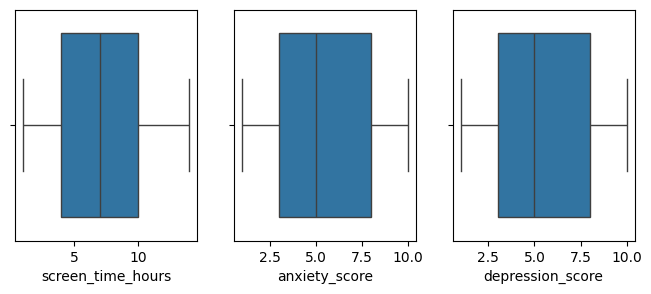

In [46]:
plt.figure(figsize=(8,3))
plt.subplot(1,3,1)
sns.boxplot(x=df["screen_time_hours"])
plt.subplot(1,3,2)
sns.boxplot(x=df["anxiety_score"])
plt.subplot(1,3,3)
sns.boxplot(x=df["depression_score"])
plt.show()

<Axes: xlabel='depression_score', ylabel='Count'>

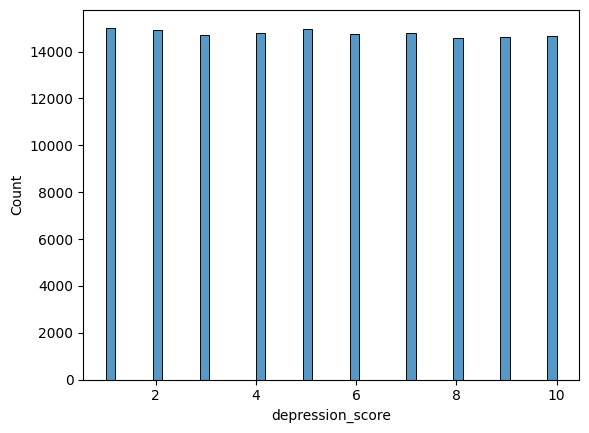

In [50]:
sns.histplot(x=df["depression_score"])

<Axes: xlabel='screen_time_hours', ylabel='depression_score'>

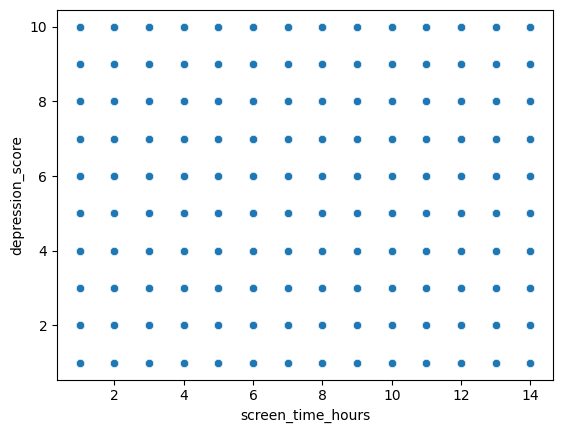

In [54]:
sns.scatterplot(y=df['depression_score'],x=df['screen_time_hours'])

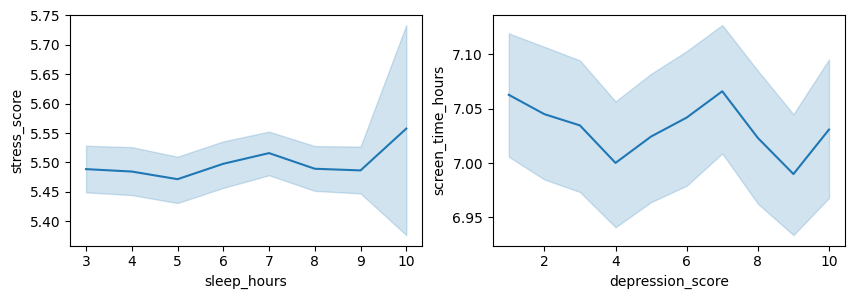

In [64]:
plt.figure(figsize=(10,3))
plt.subplot(1,2,1)
sns.lineplot(x=df["sleep_hours"],y=df["stress_score"])
plt.subplot(1,2,2)
sns.lineplot(x=df["depression_score"],y=df["screen_time_hours"])
plt.show()


In [65]:
# A. Average stress and sleep metrics by Gender
gender_stats = df.groupby('gender')[['stress_score', 'sleep_hours', 'depression_score']].mean()
print(gender_stats)

# B. Average work hours and screen time per Occupation
occupation_workload = df.groupby('occupation')[['work_hours_per_week', 'screen_time_hours']].mean()
print(occupation_workload)

# C. Mental health risk counts grouped by Country
country_risk_counts = df.groupby(['country', 'mental_health_risk']).size().unstack(fill_value=0)
print(country_risk_counts)


                   stress_score  sleep_hours  depression_score
gender                                                        
Female                 5.503152     6.055846          5.485051
Male                   5.486861     6.058936          5.477974
Non-binary             5.484599     6.054298          5.469508
Prefer not to say      5.488855     6.026435          5.482219
                   work_hours_per_week  screen_time_hours
occupation                                               
Data Scientist               45.073129           7.008707
Designer                     44.970051           7.033846
Doctor                       45.099423           7.054743
Freelancer                   45.068685           7.013683
Manager                      44.940971           7.029548
Researcher                   44.979934           7.045624
Software Engineer            45.224911           7.030248
Student                      45.022107           7.043466
Teacher                      45.065342    

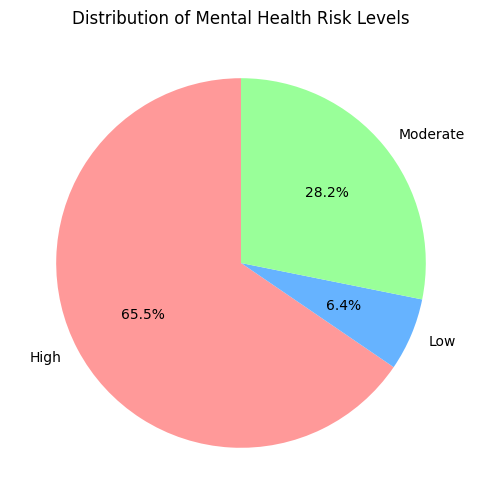

In [67]:
# A. Distribution of Mental Health Risk Levels
risk_distribution = df.groupby('mental_health_risk').size()

plt.figure(figsize=(6, 6))
risk_distribution.plot(kind='pie', autopct='%1.1f%%', colors=['#ff9999','#66b3ff','#99ff99'], startangle=90)
plt.title('Distribution of Mental Health Risk Levels')
plt.ylabel('') # Hides the default column name label on the y-axis
plt.show()



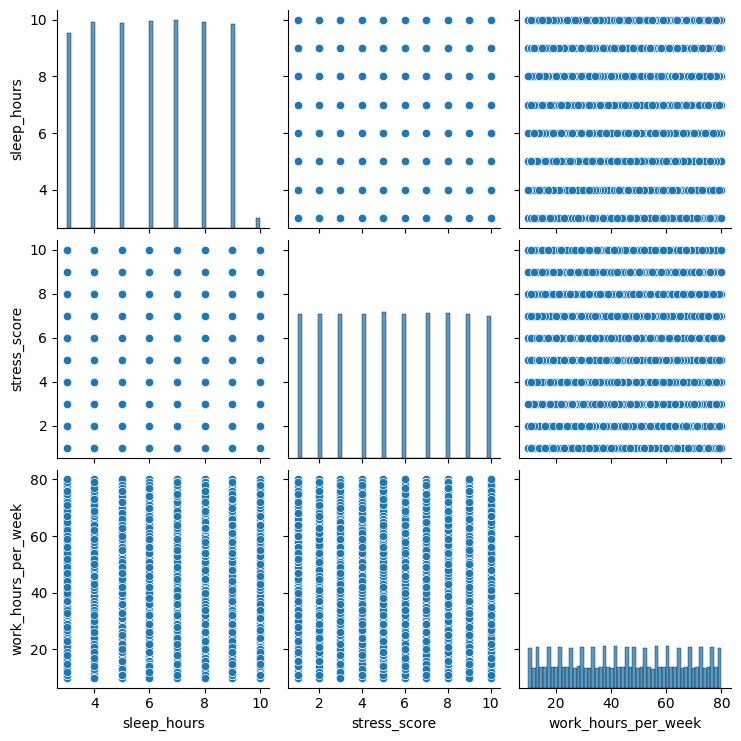

In [70]:
sns.pairplot(df[["sleep_hours","stress_score","work_hours_per_week"]])